1. Hipo
2. Params
3. Minizar costo
4. validar y entrenar

### Supervisado
- datos etiquetados
- feedback directo
- prediccion

## Regresion lineal
m datos de entranmiento, m pares de datos xy.
se puede definir un modelo lineal como:
$$ h(X) = \theta_0 + theta_1 * x_1 $$
donde theta 0 y theta 1 son parametros.
para optimizar se define una funcion de costo J(theta0, theta1)
$$  J(\theta_0, \theta_1) = \frac{1}{2m} \sum_{i=1}^{m} (h_\theta(x^{(i)}) - y^{(i)})^2 $$
el metodo mas conocido es el gradiente descendente.

# 1. Construir un dataframe con un conjunto de datos lineales simples.

In [2]:
# Generamos datos lineales sin ruido para estudiar el caso ideal.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

x = np.linspace(0, 10, 100)
y = 2/3 * x + 1/4

# ahora los agrego al df

df = pd.DataFrame({'x': x, 'y': y})
df.head()

,x,y
0,0.00000,0.25000
1,0.10101,0.31734
2,0.20202,0.38468
3,0.30303,0.45202
4,0.40404,0.51936


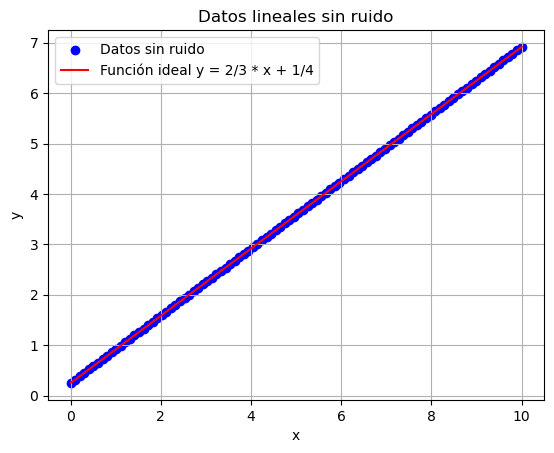

In [3]:
# Graficamos el caso ideal usado como referencia.
plt.scatter(df['x'], df['y'], color='blue', label='Datos sin ruido')
plt.plot(x, 2/3 * x + 1/4, color='red', label='Función ideal y = 2/3 * x + 1/4')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Datos lineales sin ruido')
plt.legend()
plt.grid()

# 2. Defina una función que calcule la función de coste cuadrática para un modelo de regresión lineal.

In [4]:
# J usa la definicion solicitada: 1/(2m) por la suma del error cuadratico.
def J(m, b):
    errores = df['y'] - (m * df['x'] + b)
    return np.sum(errores**2) / (2 * len(df))

# 3. Fijando inicialmente $\theta_0=0$, evalúe y grafique la función de coste para diferentes valores de $\theta_1$. Determine el valor que minimiza la función de coste y grafique la recta obtenida sobre los datos.

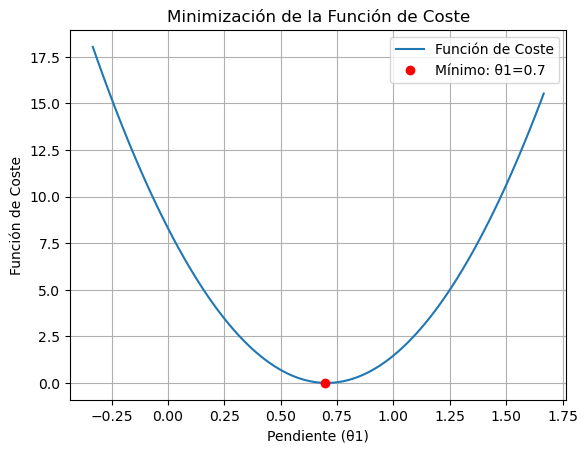

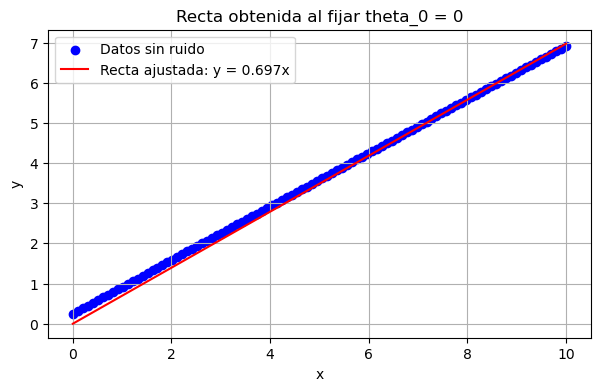

In [5]:
# Ahora fijamos el intercepto en 0, evaluamos la funcion de coste para diferentes valores de la pendiente y graficamos los resultados.

b = 0
m_values = np.linspace(2/3-1, 2/3+1, 100)
J_values = [J(m, b) for m in m_values]
# el minimo es:
min_m = m_values[np.argmin(J_values)]

plt.plot(m_values, J_values, label='Función de Coste')
plt.plot(min_m, J(min_m, b), 'ro', label=f'Mínimo: θ1={min_m:.2g}')
plt.legend()
plt.xlabel('Pendiente (θ1)')
plt.ylabel('Función de Coste')
plt.title('Minimización de la Función de Coste')
plt.grid()
plt.show()

# La recta correspondiente al minimo con theta_0 fijado en cero.
plt.figure(figsize=(7, 4))
plt.scatter(df['x'], df['y'], color='blue', label='Datos sin ruido')
plt.plot(df['x'], min_m * df['x'] + b, color='red',
         label=f'Recta ajustada: y = {min_m:.3f}x')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Recta obtenida al fijar theta_0 = 0')
plt.legend()
plt.grid()
plt.show()

# 4. Permita ahora que tanto $\theta_0$ como $\theta_1$ varíen. Construya una malla con `np.meshgrid`, evalúe la función de coste en cada punto y represente su superficie y curvas de nivel.

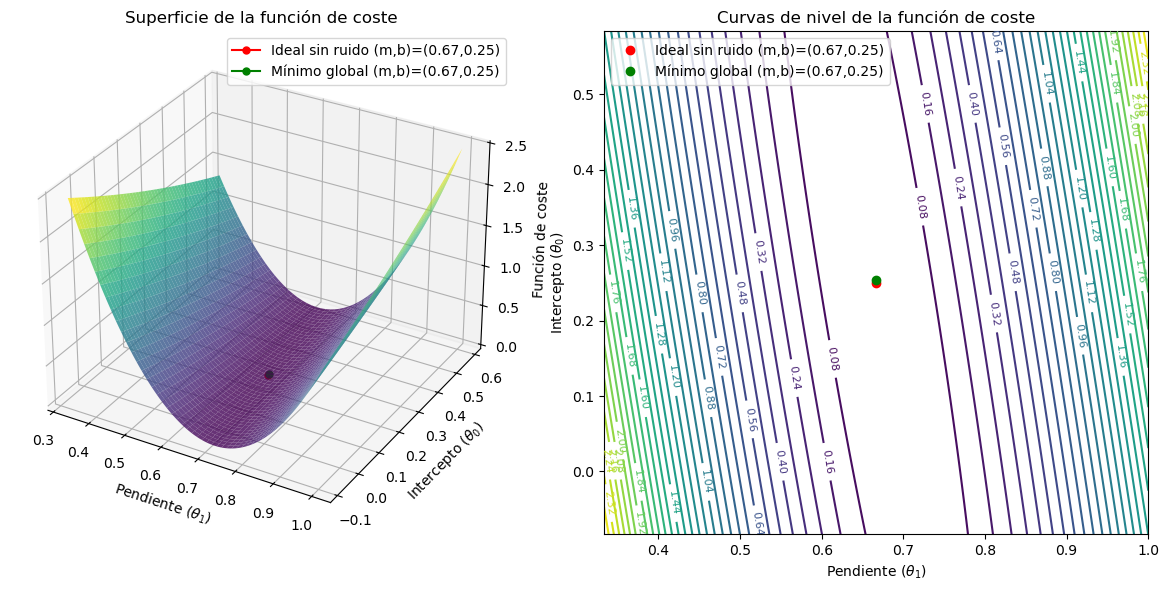

In [6]:
# θ1 = pendiente (m) y θ0 = intercepto (b)
m_values = np.linspace(2/3 - 1/3, 2/3 + 1/3, 500)
b_values = np.linspace(1/4 - 1/3, 1/4 + 1/3, 500)

M, B = np.meshgrid(m_values, b_values)

# Evaluar J en cada combinación y recuperar la forma de la malla
J_values = np.array([
    J(m, b) for m, b in zip(M.ravel(), B.ravel())
]).reshape(M.shape)

fig = plt.figure(figsize=(12, 6))

# Superficie 3D
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(M, B, J_values, cmap="viridis", alpha=0.8)
#Ademas en la superficie 3d quierp ploetear el punto (2/3, 1/4, J(2/3, 1/4)
ax.plot([2/3], [1/4], [J(2/3, 1/4)], marker='o', markersize=5, color='red', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
# Tambien graficamos el minimo global de la funcion de coste, que es el punto, lo calculamos y graficamos
min_index = np.unravel_index(np.argmin(J_values), J_values.shape)
min_m = M[min_index]
min_b = B[min_index]
ax.plot([min_m], [min_b], [J(min_m, min_b)], marker='o', markersize=5, color='green', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax.set_xlabel("Pendiente ($\\theta_1$)")
ax.set_ylabel("Intercepto ($\\theta_0$)")
ax.set_zlabel("Función de coste")
ax.set_title("Superficie de la función de coste")
ax.legend()

# Curvas de nivel
ax2 = fig.add_subplot(1, 2, 2)
contornos = ax2.contour(M, B, J_values, levels=35, cmap="viridis")
ax2.clabel(contornos, inline=True, fontsize=8)
ax2.plot(2/3, 1/4, 'ro', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
ax2.plot(min_m, min_b, 'go', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax2.set_xlabel("Pendiente ($\\theta_1$)")
ax2.set_ylabel("Intercepto ($\\theta_0$)")
ax2.set_title("Curvas de nivel de la función de coste")
ax2.legend()

plt.tight_layout()
plt.show()

# 5. Interprete geométricamente la forma de la función de coste e identifique el mínimo global.

En la suoerficie de la funcion de costo notamos que el comportamiento es propio de una parabola donde la curva es mas evidente para los valores de la pedniente que para los del intercepto. Ademas al graficar en la superficie tanto los valores ideales y los obtenidos por el minimo global, se puede notar que ambos se encuentran relativamente cerca, lo cual indica no solo que se hizo una buena optimizacion, sino que ademas el ruido no es tal que afecte de manera significativa el resultado final.

# 6. Repita el procedimiento para un conjunto de datos con ruido y compare los resultados con el caso ideal.

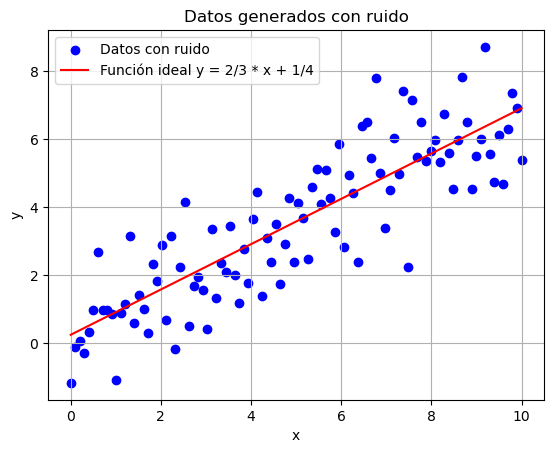

In [7]:
# Ahora vamos a agregar ruido a los datos tanto en la pendiente como en el intercepto.
x = np.linspace(0, 10, 100)
y = 2/3 * np.random.normal(1, 0.25, size=x.shape)* x + 1/4 + np.random.normal(0, 1, size=x.shape)
# ahora los agrego al df

df = pd.DataFrame({'x': x, 'y': y})
# ahora los ploeto para ver como estan, ademas puedo mostrar cual fue la funcion ideal sin ruido que use para generar los datos, que es y = 2/3 * x + 1/4
plt.scatter(df['x'], df['y'], color='blue', label='Datos con ruido')
plt.plot(x, 2/3 * x + 1/4, color='red', label='Función ideal y = 2/3 * x + 1/4')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Datos generados con ruido')
plt.legend()
plt.grid()

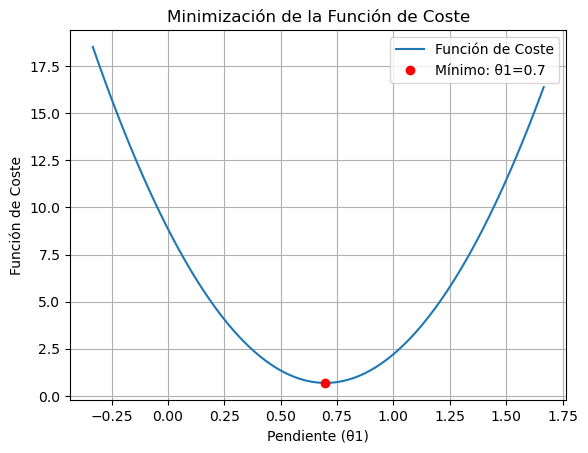

In [8]:
# Ahora fijamos el intercepto en 0, evaluamos la funcion de coste para diferentes valores de la pendiente y graficamos los resultados.

b = 0
m_values = np.linspace(2/3-1, 2/3+1, 100)
J_values = [J(m, b) for m in m_values]
# el minimo es:
min_m = m_values[np.argmin(J_values)]

plt.plot(m_values, J_values, label='Función de Coste')
plt.plot(min_m, J(min_m, b), 'ro', label=f'Mínimo: θ1={min_m:.2g}')
plt.legend()
plt.xlabel('Pendiente (θ1)')
plt.ylabel('Función de Coste')
plt.title('Minimización de la Función de Coste')
plt.grid()
plt.show()

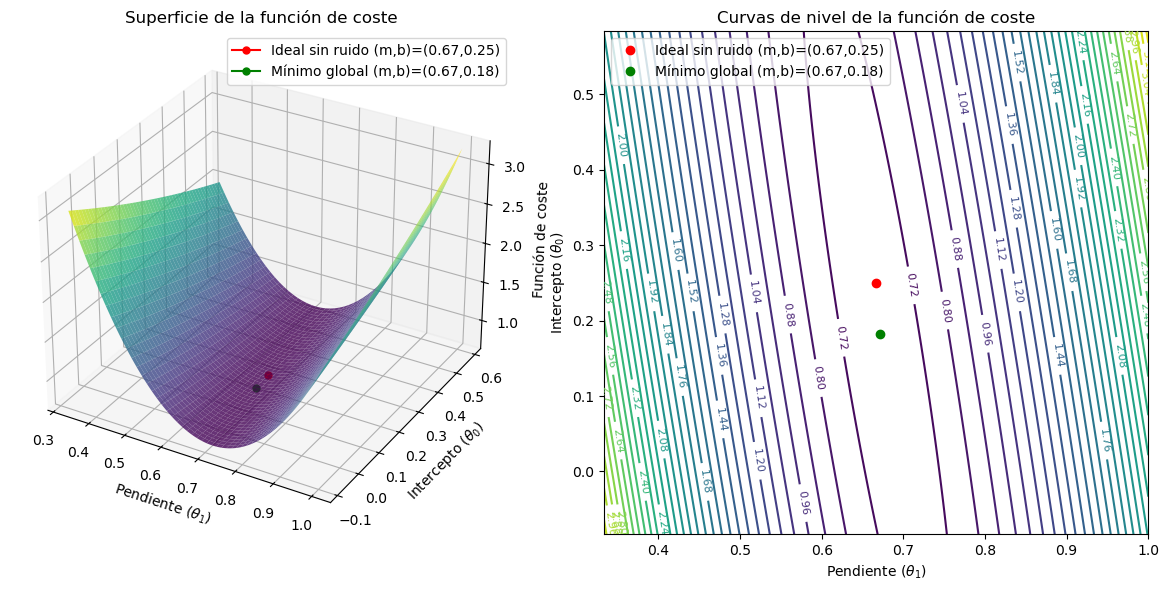

In [9]:
# θ1 = pendiente (m) y θ0 = intercepto (b)
m_values = np.linspace(2/3 - 1/3, 2/3 + 1/3, 500)
b_values = np.linspace(1/4 - 1/3, 1/4 + 1/3, 500)

M, B = np.meshgrid(m_values, b_values)

# Evaluar J en cada combinación y recuperar la forma de la malla
J_values = np.array([
    J(m, b) for m, b in zip(M.ravel(), B.ravel())
]).reshape(M.shape)

fig = plt.figure(figsize=(12, 6))

# Superficie 3D
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(M, B, J_values, cmap="viridis", alpha=0.8)
#Ademas en la superficie 3d quierp ploetear el punto (2/3, 1/4, J(2/3, 1/4)
ax.plot([2/3], [1/4], [J(2/3, 1/4)], marker='o', markersize=5, color='red', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
# Tambien graficamos el minimo global de la funcion de coste, que es el punto, lo calculamos y graficamos
min_index = np.unravel_index(np.argmin(J_values), J_values.shape)
min_m = M[min_index]
min_b = B[min_index]
ax.plot([min_m], [min_b], [J(min_m, min_b)], marker='o', markersize=5, color='green', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax.set_xlabel("Pendiente ($\\theta_1$)")
ax.set_ylabel("Intercepto ($\\theta_0$)")
ax.set_zlabel("Función de coste")
ax.set_title("Superficie de la función de coste")
ax.legend()

# Curvas de nivel
ax2 = fig.add_subplot(1, 2, 2)
contornos = ax2.contour(M, B, J_values, levels=35, cmap="viridis")
ax2.clabel(contornos, inline=True, fontsize=8)
ax2.plot(2/3, 1/4, 'ro', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
ax2.plot(min_m, min_b, 'go', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax2.set_xlabel("Pendiente ($\\theta_1$)")
ax2.set_ylabel("Intercepto ($\\theta_0$)")
ax2.set_title("Curvas de nivel de la función de coste")
ax2.legend()

plt.tight_layout()
plt.show()

la diferencia entre el caso ideal y el caso con ruido es que en el caso con ruido, los valores de la pendiente y del intercepto obtenidos por el minimo global no son exactamente iguales a los valores ideales, pero se encuentran relativamente cerca. A nivel general la superficie entera se ve desplazada.

# 7. Analice el efecto de introducir un valor atípico en el conjunto de datos. Discuta cómo cambia la solución y qué limitaciones presenta la función de coste cuadrática.

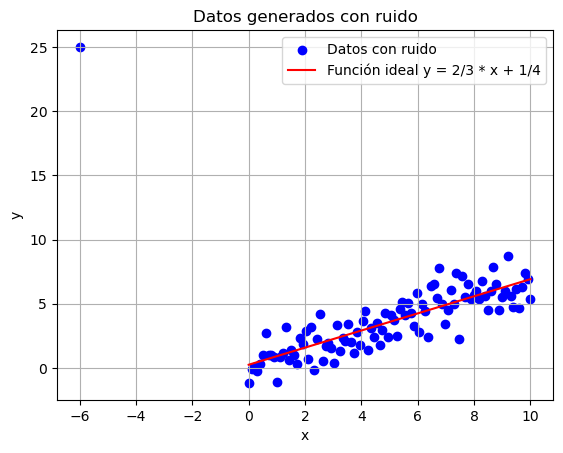

In [10]:
# Vamos a intruducir un valor atípico en el conjunto de datos, para esto vamos a agregar un punto con coordenadas (-6, 25) al conjunto de datos original y luego recalcularemos la función de coste y el mínimo global.
# Agregamos el valor atípico
outlier = pd.DataFrame({'x': [-6], 'y': [25]})
df = pd.concat([df, outlier], ignore_index=True)
plt.scatter(df['x'], df['y'], color='blue', label='Datos con ruido')
plt.plot(x, 2/3 * x + 1/4, color='red', label='Función ideal y = 2/3 * x + 1/4')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Datos generados con ruido')
plt.legend()
plt.grid()

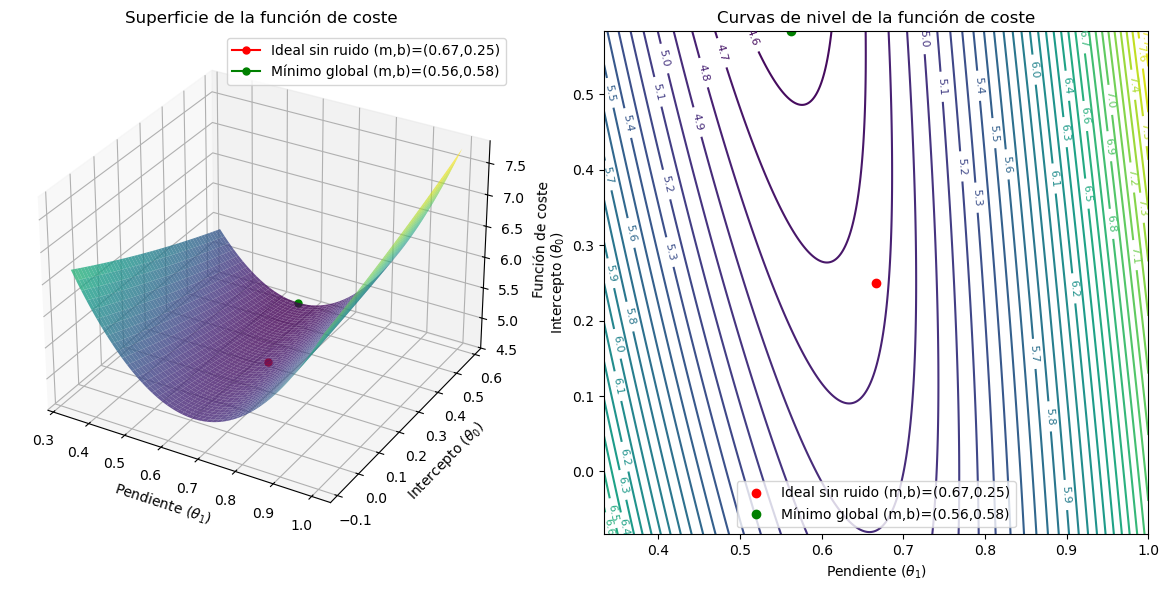

In [11]:
# θ1 = pendiente (m) y θ0 = intercepto (b)
m_values = np.linspace(2/3 - 1/3, 2/3 + 1/3, 500)
b_values = np.linspace(1/4 - 1/3, 1/4 + 1/3, 500)

M, B = np.meshgrid(m_values, b_values)

# Evaluar J en cada combinación y recuperar la forma de la malla
J_values = np.array([
    J(m, b) for m, b in zip(M.ravel(), B.ravel())
]).reshape(M.shape)

fig = plt.figure(figsize=(12, 6))

# Superficie 3D
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(M, B, J_values, cmap="viridis", alpha=0.8)
#Ademas en la superficie 3d quierp ploetear el punto (2/3, 1/4, J(2/3, 1/4)
ax.plot([2/3], [1/4], [J(2/3, 1/4)], marker='o', markersize=5, color='red', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
# Tambien graficamos el minimo global de la funcion de coste, que es el punto, lo calculamos y graficamos
min_index = np.unravel_index(np.argmin(J_values), J_values.shape)
min_m = M[min_index]
min_b = B[min_index]
ax.plot([min_m], [min_b], [J(min_m, min_b)], marker='o', markersize=5, color='green', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax.set_xlabel("Pendiente ($\\theta_1$)")
ax.set_ylabel("Intercepto ($\\theta_0$)")
ax.set_zlabel("Función de coste")
ax.set_title("Superficie de la función de coste")
ax.legend()

# Curvas de nivel
ax2 = fig.add_subplot(1, 2, 2)
contornos = ax2.contour(M, B, J_values, levels=35, cmap="viridis")
ax2.clabel(contornos, inline=True, fontsize=8)
ax2.plot(2/3, 1/4, 'ro', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
ax2.plot(min_m, min_b, 'go', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax2.set_xlabel("Pendiente ($\\theta_1$)")
ax2.set_ylabel("Intercepto ($\\theta_0$)")
ax2.set_title("Curvas de nivel de la función de coste")
ax2.legend()

plt.tight_layout()
plt.show()

notamos que al introducir un valor atipico, la superficie de la funcion de costo se ve afectada, y el minimo global cambia, lo cual indica que la funcion de costo cuadratica es sensible a valores atipicos. 

# 8. Compare el ajuste obtenido con un modelo lineal sobre un conjunto de datos no lineales. Discuta si minimizar la función de coste garantiza que el modelo sea adecuado.

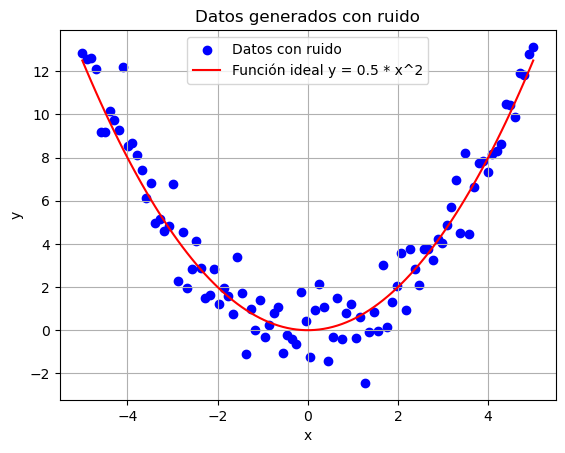

In [12]:
# Ahora veremos que pasa si intentamos ajustar un modelo lineal a un conjunto de datos no lineales. Para esto, vamos a generar un conjunto de datos que siga una relación cuadrática y luego intentaremos ajustar un modelo lineal a estos datos.
# Generamos datos no lineales
x = np.linspace(-5, 5, 100)
y = 0.5 * x**2 + np.random.normal(0, 1, size=x.shape)  # Agregamos algo de ruido
df = pd.DataFrame({'x': x, 'y': y})
plt.scatter(df['x'], df['y'], color='blue', label='Datos con ruido')
plt.plot(x, 0.5 * x**2, color='red', label='Función ideal y = 0.5 * x^2')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Datos generados con ruido')
plt.legend()
plt.grid()

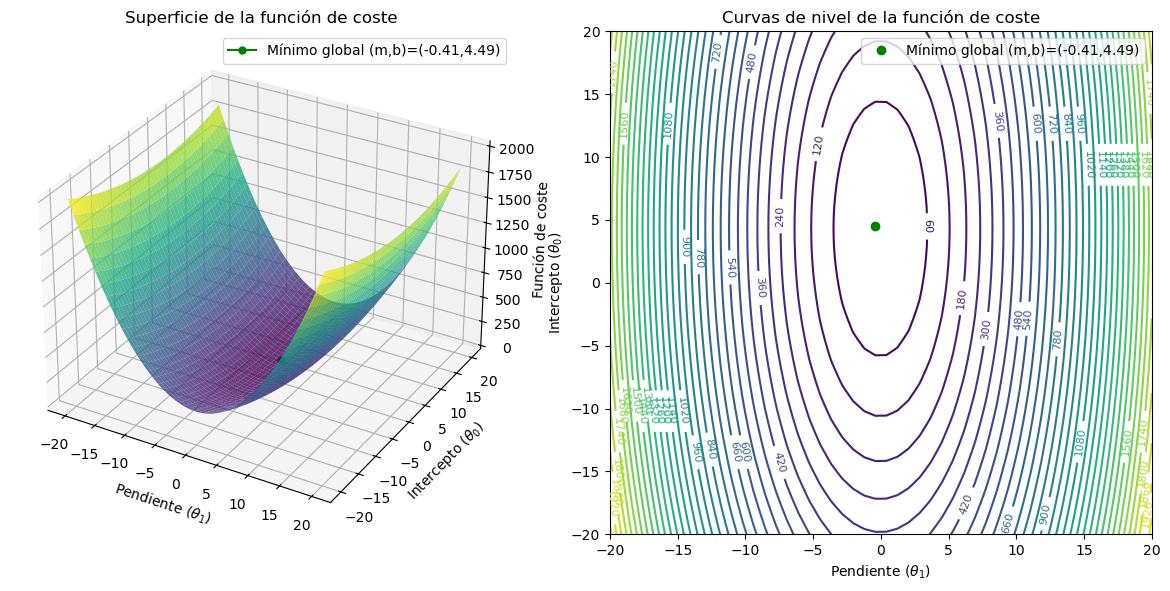

In [13]:
# θ1 = pendiente (m) y θ0 = intercepto (b)
m_values = np.linspace(-20, 20, 50)
b_values = np.linspace(-20, 20, 50)

M, B = np.meshgrid(m_values, b_values)

# Evaluar J en cada combinación y recuperar la forma de la malla
J_values = np.array([
    J(m, b) for m, b in zip(M.ravel(), B.ravel())
]).reshape(M.shape)

fig = plt.figure(figsize=(12, 6))

# Superficie 3D
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_surface(M, B, J_values, cmap="viridis", alpha=0.8)
#Ademas en la superficie 3d quierp ploetear el punto (2/3, 1/4, J(2/3, 1/4)
#ax.plot([2/3], [1/4], [J(2/3, 1/4)], marker='o', markersize=5, color='red', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
# Tambien graficamos el minimo global de la funcion de coste, que es el punto, lo calculamos y graficamos
min_index = np.unravel_index(np.argmin(J_values), J_values.shape)
min_m = M[min_index]
min_b = B[min_index]
ax.plot([min_m], [min_b], [J(min_m, min_b)], marker='o', markersize=5, color='green', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax.set_xlabel("Pendiente ($\\theta_1$)")
ax.set_ylabel("Intercepto ($\\theta_0$)")
ax.set_zlabel("Función de coste")
ax.set_title("Superficie de la función de coste")
ax.legend()

# Curvas de nivel
ax2 = fig.add_subplot(1, 2, 2)
contornos = ax2.contour(M, B, J_values, levels=35, cmap="viridis")
ax2.clabel(contornos, inline=True, fontsize=8)
#ax2.plot(2/3, 1/4, 'ro', label='Ideal sin ruido (m,b)=({:.2f},{:.2f})'.format(2/3, 1/4))
ax2.plot(min_m, min_b, 'go', label='Mínimo global (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))

ax2.set_xlabel("Pendiente ($\\theta_1$)")
ax2.set_ylabel("Intercepto ($\\theta_0$)")
ax2.set_title("Curvas de nivel de la función de coste")
ax2.legend()

plt.tight_layout()
plt.show()

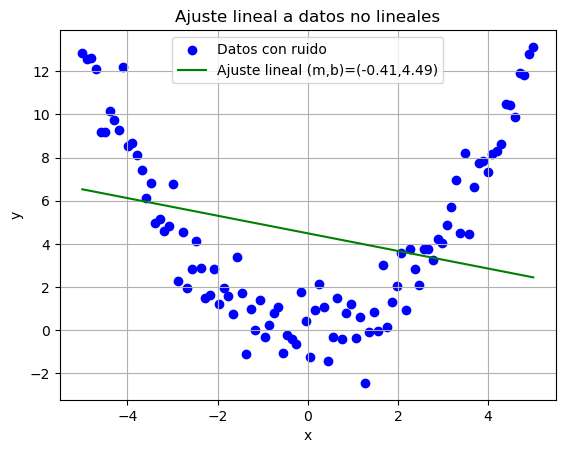

In [14]:
# graficamos el ajuste lineal a los datos cuadraticos
plt.scatter(df['x'], df['y'], color='blue', label='Datos con ruido')
plt.plot(df['x'], min_m * df['x'] + min_b, color='green', label='Ajuste lineal (m,b)=({:.2f},{:.2f})'.format(min_m, min_b))
plt.xlabel('x')
plt.ylabel('y')
plt.title('Ajuste lineal a datos no lineales')
plt.legend()    
plt.grid()
plt.show()

Terrible, el ajuste lineal no es adecuado para un conjunto de datos no lineales, ya que la recta obtenida no sigue la tendencia de los datos. Minimizar la función de coste no garantiza que el modelo sea adecuado, ya que puede llevar a un ajuste incorrecto si el modelo no es apropiado para los datos.

# 9. Obtenga la expresion teorica de la funcion de coste en el caso con un parametro y con dos parametros, e interprete el significado de sus minimos.

## Caso con un parametro

Si se fija $\theta_0=0$, la hipotesis es $h_\theta(x)=\theta_1x$. Al expandir la funcion de coste se obtiene:

$$J(\theta_1)=\frac{1}{2m}\left(\theta_1^2\sum_{i=1}^{m}(x^{(i)})^2-2\theta_1\sum_{i=1}^{m}x^{(i)}y^{(i)}+\sum_{i=1}^{m}(y^{(i)})^2\right).$$

Es una parabola en $\theta_1$. Al igualar su derivada a cero, si $\sum_i(x^{(i)})^2>0$, se obtiene:

$$\theta_1^*=\frac{\sum_{i=1}^{m}x^{(i)}y^{(i)}}{\sum_{i=1}^{m}(x^{(i)})^2}. $$

Este minimo es la pendiente que hace minima la suma de errores cuadrados cuando la recta debe pasar por el origen.

## Caso con dos parametros

Para $h_\theta(x)=\theta_0+\theta_1x$:

$$J(\theta_0,\theta_1)=\frac{1}{2m}\sum_{i=1}^{m}(\theta_0+\theta_1x^{(i)}-y^{(i)})^2. $$

Sus derivadas son:

$$\frac{\partial J}{\partial\theta_0}=\frac{1}{m}\sum_i(\theta_0+\theta_1x^{(i)}-y^{(i)}),\qquad\frac{\partial J}{\partial\theta_1}=\frac{1}{m}\sum_i x^{(i)}(\theta_0+\theta_1x^{(i)}-y^{(i)}).$$

Al anular ambas derivadas se obtienen las ecuaciones normales. Si los valores de $x$ no son todos iguales, la solucion es unica:

$$\theta_1^*=\frac{\sum_i(x^{(i)}-\bar{x})(y^{(i)}-\bar{y})}{\sum_i(x^{(i)}-\bar{x})^2},\qquad\theta_0^*=\bar{y}-\theta_1^*\bar{x}. $$

Geometricamente, $J$ es un paraboloide convexo sobre el plano de parametros. Por eso su minimo es global y corresponde a la recta de minimos cuadrados.

# 10. Construya un algoritmo en el que emplee el gradiente descendente para determinar el mínimo de una función. Determine dicho mínimo con un error $\epsilon$ de $10^{-4}$. Pruebe su algoritmo para

$$
f(x)=(x-4)^2
$$

y al menos tres valores diferentes de $\alpha$.


In [15]:
def descenso_gradiente_1d(funcion, gradiente, x_inicial, alpha, epsilon=1e-4, max_iter=10_000):
    """Minimiza una funcion derivable y retorna el minimo, la trayectoria y las iteraciones."""
    x_actual = float(x_inicial)
    trayectoria = [x_actual]

    for iteracion in range(1, max_iter + 1):
        x_siguiente = x_actual - alpha * gradiente(x_actual)
        trayectoria.append(x_siguiente)
        if abs(x_siguiente - x_actual) < epsilon:
            return x_siguiente, np.array(trayectoria), iteracion
        x_actual = x_siguiente

    raise RuntimeError('El algoritmo no convergio con los parametros indicados.')

f = lambda x: (x - 4) ** 2
grad_f = lambda x: 2 * (x - 4)

resultados_1d = []
trayectorias_1d = {}
for alpha in (0.05, 0.10, 0.40, 0.80, 1.00):
    minimo, trayectoria, iteraciones = descenso_gradiente_1d(f, grad_f, x_inicial=-6, alpha=alpha)
    resultados_1d.append({
        'alpha': alpha,
        'minimo_estimado': minimo,
        'f(minimo)': f(minimo),
        'iteraciones': iteraciones,
        'error_abs': abs(minimo - 4),
    })
    trayectorias_1d[alpha] = trayectoria

pd.DataFrame(resultados_1d)

RuntimeError: El algoritmo no convergio con los parametros indicados.

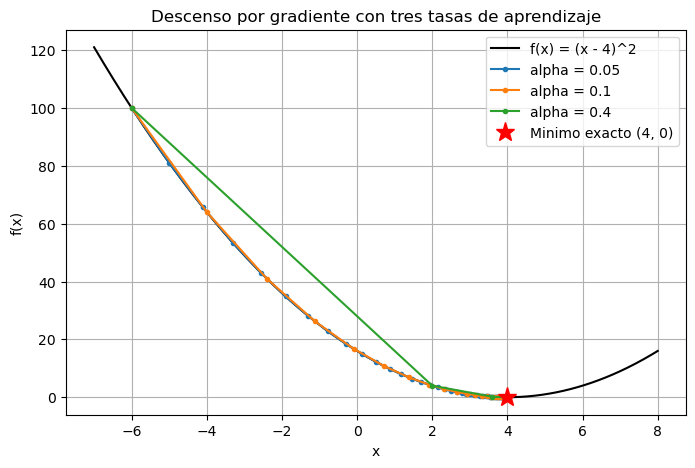

In [ ]:
x_grafica = np.linspace(-7, 8, 400)
plt.figure(figsize=(8, 5))
plt.plot(x_grafica, f(x_grafica), color='black', label='f(x) = (x - 4)^2')
for alpha, trayectoria in trayectorias_1d.items():
    plt.plot(trayectoria, f(trayectoria), 'o-', markersize=3, label=f'alpha = {alpha}')
plt.plot(4, 0, 'r*', markersize=14, label='Minimo exacto (4, 0)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Descenso por gradiente con tres tasas de aprendizaje')
plt.legend()
plt.grid()
plt.show()

Los tres valores de $\alpha$ convergen al minimo $x=4$ con un error menor que $10^{-4}$. Una tasa mayor acelera la convergencia mientras se mantenga en el intervalo estable $0 < \alpha < 1$ para esta funcion cuadratica. Con $\alpha=1$ el algoritmo oscila y con valores mayores diverge.

# 11. Encuentre el minimo de $F(x,y)$ por descenso por gradiente y represente la funcion.

$$F(x,y)=\sin\left(\frac{1}{2}x^2-\frac{1}{4}y^2+3\right)\cos(2x+1-e^y).$$

In [ ]:
def F(x, y):
    a = 0.5 * x**2 - 0.25 * y**2 + 3
    b = 2 * x + 1 - np.exp(y)
    return np.sin(a) * np.cos(b)


def gradiente_F(x, y):
    a = 0.5 * x**2 - 0.25 * y**2 + 3
    b = 2 * x + 1 - np.exp(y)
    d_dx = x * np.cos(a) * np.cos(b) - 2 * np.sin(a) * np.sin(b)
    d_dy = -0.5 * y * np.cos(a) * np.cos(b) + np.exp(y) * np.sin(a) * np.sin(b)
    return np.array([d_dx, d_dy])


def descenso_gradiente_2d(theta_inicial, alpha=0.05, epsilon=1e-8, max_iter=10_000):
    """Minimiza F con retroceso de paso para asegurar descenso en cada iteracion."""
    theta = np.asarray(theta_inicial, dtype=float)
    trayectoria = [theta.copy()]

    for iteracion in range(1, max_iter + 1):
        gradiente = gradiente_F(*theta)
        if np.linalg.norm(gradiente) < epsilon:
            return theta, np.array(trayectoria), iteracion

        paso = alpha
        valor_actual = F(*theta)
        while F(*(theta - paso * gradiente)) > valor_actual - 1e-4 * paso * np.dot(gradiente, gradiente):
            paso *= 0.5
            if paso < 1e-12:
                return theta, np.array(trayectoria), iteracion

        theta_siguiente = theta - paso * gradiente
        trayectoria.append(theta_siguiente.copy())
        if np.linalg.norm(theta_siguiente - theta) < epsilon:
            return theta_siguiente, np.array(trayectoria), iteracion
        theta = theta_siguiente

    return theta, np.array(trayectoria), max_iter

# F es no convexa. Usamos varios puntos iniciales para reducir el riesgo de quedar en un minimo local.
generador = np.random.default_rng(7)
inicios = generador.uniform(low=(-4, -3), high=(4, 2), size=(30, 2))
soluciones = []
for inicio in inicios:
    theta, trayectoria, iteraciones = descenso_gradiente_2d(inicio)
    soluciones.append((F(*theta), theta, trayectoria, iteraciones))

valor_minimo, theta_minimo, trayectoria_minima, iteraciones_minimas = min(soluciones, key=lambda solucion: solucion[0])
print(f'Minimo encontrado: F({theta_minimo[0]:.6f}, {theta_minimo[1]:.6f}) = {valor_minimo:.10f}')
print(f'Iteraciones para la mejor trayectoria: {iteraciones_minimas}')
print('Como -1 <= F(x, y) <= 1 y el valor encontrado es aproximadamente -1, es un minimo global numerico.')

Minimo encontrado: F(-4.166615, 1.655012) = -1.0000000000
Iteraciones para la mejor trayectoria: 41
Como -1 <= F(x, y) <= 1 y el valor encontrado es aproximadamente -1, es un minimo global numerico.


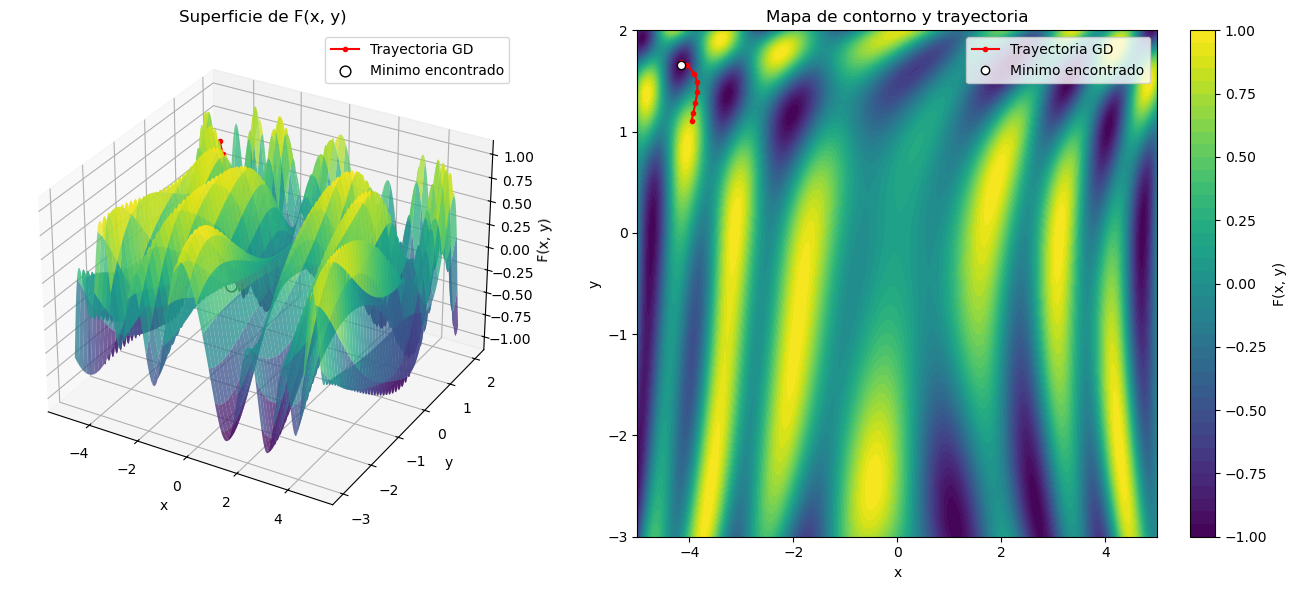

In [ ]:
x_malla = np.linspace(-5, 5, 220)
y_malla = np.linspace(-3, 2, 220)
X_malla, Y_malla = np.meshgrid(x_malla, y_malla)
Z_malla = F(X_malla, Y_malla)

fig = plt.figure(figsize=(14, 6))
ax_superficie = fig.add_subplot(1, 2, 1, projection='3d')
ax_superficie.plot_surface(X_malla, Y_malla, Z_malla, cmap='viridis', alpha=0.75, linewidth=0)
ax_superficie.plot(trayectoria_minima[:, 0], trayectoria_minima[:, 1],
                   F(trayectoria_minima[:, 0], trayectoria_minima[:, 1]), 'r.-', label='Trayectoria GD')
ax_superficie.scatter(*theta_minimo, valor_minimo, color='white', edgecolor='black', s=60, label='Minimo encontrado')
ax_superficie.set_xlabel('x')
ax_superficie.set_ylabel('y')
ax_superficie.set_zlabel('F(x, y)')
ax_superficie.set_title('Superficie de F(x, y)')
ax_superficie.legend()

ax_contorno = fig.add_subplot(1, 2, 2)
contornos = ax_contorno.contourf(X_malla, Y_malla, Z_malla, levels=40, cmap='viridis')
fig.colorbar(contornos, ax=ax_contorno, label='F(x, y)')
ax_contorno.plot(trayectoria_minima[:, 0], trayectoria_minima[:, 1], 'r.-', label='Trayectoria GD')
ax_contorno.plot(*theta_minimo, 'wo', markeredgecolor='black', label='Minimo encontrado')
ax_contorno.set_xlabel('x')
ax_contorno.set_ylabel('y')
ax_contorno.set_title('Mapa de contorno y trayectoria')
ax_contorno.legend()
plt.tight_layout()
plt.show()

La funcion tiene varios valles por sus componentes trigonometricas y, por tanto, no es convexa. El descenso por gradiente depende del punto inicial; por eso se probaron 30 inicios y se reporto la mejor solucion. El retroceso de paso evita que una actualizacion aumente el valor de la funcion.

# 12. Regresion lineal propia, comparacion con sklearn y paquete Python

La implementacion reutilizable se encuentra en el paquete regresion-lineal-gd, dentro de src/regresion_lineal_gd. Incluye la hipotesis lineal, la funcion de coste, el descenso por gradiente y la funcion principal de ajuste.

In [ ]:
from pathlib import Path
import sys

# Permite usar el paquete desde el notebook antes de instalarlo con pip.
ruta_src = Path('src').resolve()
if str(ruta_src) not in sys.path:
    sys.path.insert(0, str(ruta_src))

from regresion_lineal_gd import fit_linear_regression
from sklearn.linear_model import LinearRegression

generador = np.random.default_rng(42)
X_lab = np.linspace(0, 1, 100)
y_lab = 0.2 + 0.2 * X_lab + 0.02 * generador.random(100)

resultado_propio = fit_linear_regression(
    X_lab, y_lab, learning_rate=0.5, tolerance=1e-10, max_iter=100_000
)
modelo_sklearn = LinearRegression().fit(X_lab.reshape(-1, 1), y_lab)

comparacion = pd.DataFrame({
    'modelo': ['Descenso por gradiente', 'sklearn LinearRegression'],
    'intercepto': [resultado_propio.intercept, modelo_sklearn.intercept_],
    'pendiente': [resultado_propio.slope, modelo_sklearn.coef_[0]],
    'coste_J': [resultado_propio.cost,
                 np.mean((modelo_sklearn.predict(X_lab.reshape(-1, 1)) - y_lab) ** 2) / 2],
})
comparacion

,modelo,intercepto,pendiente,coste_J
0,Descenso por gradiente,0.211789,0.19589,0.000014
1,sklearn LinearRegression,0.211789,0.19589,0.000014


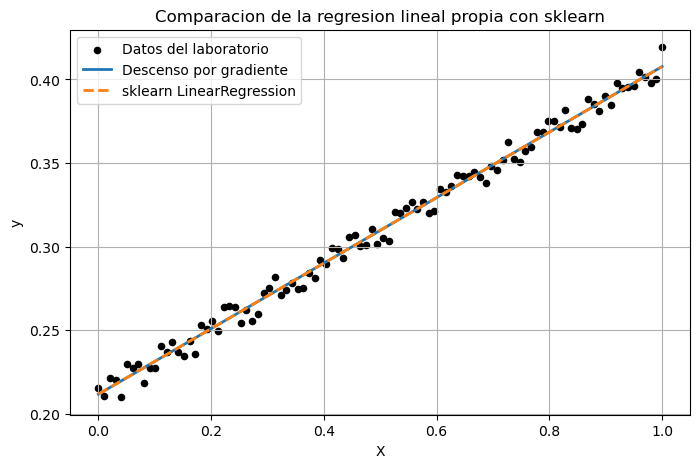

Iteraciones del ajuste propio: 500
Las diferencias numericas son pequenas porque ambos minimizan la misma funcion cuadratica.


In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(X_lab, y_lab, color='black', s=20, label='Datos del laboratorio')
plt.plot(X_lab, resultado_propio.predict(X_lab), color='tab:blue', linewidth=2,
         label='Descenso por gradiente')
plt.plot(X_lab, modelo_sklearn.predict(X_lab.reshape(-1, 1)), '--', color='tab:orange', linewidth=2,
         label='sklearn LinearRegression')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Comparacion de la regresion lineal propia con sklearn')
plt.legend()
plt.grid()
plt.show()

print(f'Iteraciones del ajuste propio: {resultado_propio.iterations}')
print('Las diferencias numericas son pequenas porque ambos minimizan la misma funcion cuadratica.')

El paquete es instalable con `pip install .` desde esta carpeta. El archivo README.md describe la instalacion y example.py contiene un ejemplo ejecutable con los datos del laboratorio.